# 01 - Exploratory data analysis: SCMS delivery history
All tables come from the DuckDB model built by `make sql` (`sql/01..06`). Raw data is not committed - run `make data` first.

**Scope:** USAID / PEPFAR SCMS delivery history, one programme, scheduled 2006-2015. The buyer is a US government health-supply programme and deliveries go to PEPFAR countries (not US-domestic). On time = delivered-to-client date <= scheduled date. There is **no vendor hand-off timestamp**. Scores describe recorded delivery performance for this programme, not vendor quality overall, on limited samples.

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/scms.duckdb', read_only=True)

## Provenance and integrity

In [2]:
json.load(open('artifacts/data_manifest.json'))

{'source': 'wayback_usaid_original',
 'source_sha256': '9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a',
 'source_bytes': 3819612,
 'source_encoding': 'latin-1',
 'failed_sources_before': ['usaid_catalog: URLError: <urlopen error [SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1016)>',
  'usaid_opengov_original: HTTPError: HTTP Error 403: Forbidden'],
 'rows': 10324,
 'columns': 33,
 'canonical_csv_sha256': 'eef7bb75c031fbaee84223adcb79b308fd8f28b6ac1cc5246b818a9464837a44'}

In [3]:
con.execute('SELECT * FROM cleaning_log ORDER BY ord').df()

,ord,action,n_rows,base,detail
0,1.0,rows_in_raw_file,10324,10324,raw rows read
1,2.0,scheduled_date_unparseable,0,10324,scheduled delivery date not a date (e.g. Date ...
2,3.0,delivered_date_unparseable,0,10324,delivered-to-client date not a date: would be ...
3,4.0,recorded_date_unparseable,0,10324,delivery recorded date not a date
4,5.0,po_sent_date_not_captured,328,10324,"procurement date text ""Date Not Captured"" (kep..."
5,6.0,po_sent_date_na_from_rdc,5404,10324,"PO date ""N/A - From RDC"": line filled from SCM..."
6,7.0,pq_date_pre_pq_process,2681,10324,"PQ date text ""Pre-PQ Process"" or ""Date Not Cap..."
7,8.0,ship_mode_na_to_unknown,360,10324,"shipment mode ""N/A"" relabelled Unknown"
8,9.0,freight_numeric,6198,10324,freight is a number
9,10.0,freight_included_in_commodity_cost,1442,10324,text: Freight Included in Commodity Cost -> fr...


In [4]:
con.execute('SELECT * FROM dq_report').df()

,check_name,n,total,detail
0,lines_rows,10324,10324,raw order-line rows
1,duplicate_line_id,0,10324,duplicate ID keys
2,null_vendor,0,10324,vendor blank
3,null_country,0,10324,country blank
4,missing_delivery_dates,0,10324,scheduled or delivered date unusable
5,recorded_before_delivered,3,10324,recorded date precedes delivered date
6,delivered_after_extract_date,0,10324,delivered date after 2015-09-29 (file date)
7,scheduled_after_extract_date,5,10324,scheduled date after 2015-09-29 yet delivered ...
8,nonpositive_line_value,17,10324,line value <= 0
9,freight_text_not_numeric,4126,10324,freight is text (included / separate / reference)


## Grain of the model

In [5]:
con.execute('''SELECT 'stg_lines' t, COUNT(*) n FROM stg_lines UNION ALL SELECT 'fct_lines', COUNT(*) FROM fct_lines UNION ALL
SELECT 'fct_shipments', COUNT(*) FROM fct_shipments UNION ALL SELECT 'vendor_summary', COUNT(*) FROM vendor_summary UNION ALL
SELECT 'vendor_year_panel', COUNT(*) FROM vendor_year_panel''').df()

,t,n
0,stg_lines,10324
1,fct_lines,10324
2,fct_shipments,7030
3,vendor_summary,73
4,vendor_year_panel,268


## Who delivers what: external vendors vs the SCMS regional distribution centre

In [6]:
con.execute('''SELECT is_internal_rdc, COUNT(*) n_lines, ROUND(AVG(is_late::INT),4) late_rate, ROUND(AVG(is_severe_late::INT),4) severe_rate,
ROUND(AVG(is_exact_match::INT),3) delivered_eq_scheduled, ROUND(SUM(line_value)/1e6,1) value_usd_m FROM fct_lines GROUP BY 1''').df()

,is_internal_rdc,n_lines,late_rate,severe_rate,delivered_eq_scheduled,value_usd_m
0,False,4920,0.0526,0.0248,0.865,542.2
1,True,5404,0.1715,0.0690,0.383,1085.4


The exact-match share is high in both channels. If scheduled dates were back-filled with actual dates in some records, the on-time rate is overstated; the file cannot tell us.

## Lateness by scheduled year

,sched_year,n_lines_vendor,n_late_vendor,n_lines_rdc,n_late_rdc
0,2006,64.0,0.0,1.0,0.0
1,2007,128.0,9.0,544.0,5.0
2,2008,409.0,7.0,620.0,6.0
3,2009,622.0,14.0,631.0,31.0
4,2010,517.0,60.0,687.0,131.0
5,2011,533.0,60.0,478.0,178.0
6,2012,495.0,25.0,778.0,76.0
7,2013,602.0,46.0,670.0,182.0
8,2014,904.0,18.0,624.0,218.0
9,2015,646.0,20.0,371.0,100.0


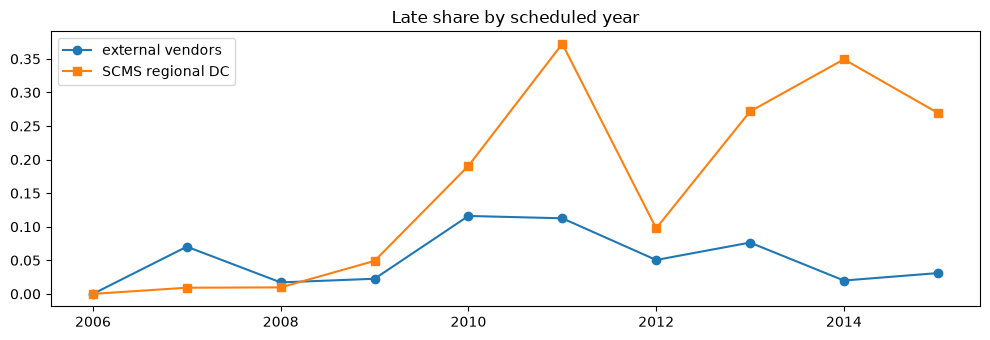

In [7]:
py = con.execute('SELECT * FROM programme_year ORDER BY sched_year').df()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(py.sched_year, py.n_late_vendor / py.n_lines_vendor, 'o-', label='external vendors')
ax.plot(py.sched_year, py.n_late_rdc / py.n_lines_rdc.where(py.n_lines_rdc > 0), 's-', label='SCMS regional DC')
ax.legend(); ax.set_title('Late share by scheduled year'); plt.tight_layout(); py[['sched_year','n_lines_vendor','n_late_vendor','n_lines_rdc','n_late_rdc']]

## Delivery offset distribution (delivered minus scheduled)

In [8]:
o = con.execute('SELECT offset_days FROM fct_lines WHERE NOT is_internal_rdc').df().offset_days
print(o.describe(percentiles=[.01, .05, .5, .9, .95, .99]).round(1)); print('late:', (o > 0).mean().round(4), ' severe (>14):', (o > 14).mean().round(4))

count    4920.0
mean       -3.5
std        25.3
min      -370.0
1%       -130.0
5%        -17.0
50%         0.0
90%         0.0
95%         1.0
99%        46.6
max       192.0
Name: offset_days, dtype: float64
late: 0.0526  severe (>14): 0.0248


## Vendor volume distribution (why shrinkage is needed)

In [9]:
s = con.execute('SELECT n_lines, value_usd FROM vendor_summary WHERE NOT is_internal_rdc').df()
print(s.n_lines.describe(percentiles=[.25, .5, .75, .9]).round(1))
print(f"vendors with <10 lines: {(s.n_lines < 10).sum()} of {len(s)}; top 10% by value hold {s.value_usd.sort_values(ascending=False).head(int(len(s)*.1)).sum()/s.value_usd.sum():.1%} of value")

count     72.0
mean      68.3
std      159.6
min        1.0
25%        1.0
50%        4.5
75%       38.8
90%      266.8
max      754.0
Name: n_lines, dtype: float64
vendors with <10 lines: 43 of 72; top 10% by value hold 82.2% of value


## Window functions on the vendor-year panel

In [10]:
con.execute('''SELECT vendor, sched_year, n_lines, late_rate, late_rate_roll3, cum_lines, volume_rank_in_year
FROM vendor_year_panel WHERE vendor = (SELECT vendor FROM vendor_summary WHERE NOT is_internal_rdc ORDER BY n_lines DESC LIMIT 1)
ORDER BY sched_year''').df()

,vendor,sched_year,n_lines,late_rate,late_rate_roll3,cum_lines,volume_rank_in_year
0,"Orgenics, Ltd",2007,8,0.375000,0.375000,8.0,9
1,"Orgenics, Ltd",2008,79,0.012658,0.045977,87.0,1
2,"Orgenics, Ltd",2009,57,0.035088,0.041667,144.0,2
3,"Orgenics, Ltd",2010,73,0.178082,0.076555,217.0,2
4,"Orgenics, Ltd",2011,83,0.048193,0.089202,300.0,2
5,"Orgenics, Ltd",2012,127,0.094488,0.102473,427.0,1
6,"Orgenics, Ltd",2013,137,0.255474,0.146974,564.0,1
7,"Orgenics, Ltd",2014,81,0.135802,0.168116,645.0,5
8,"Orgenics, Ltd",2015,109,0.155963,0.192661,754.0,2


## Lanes

In [11]:
con.execute('''SELECT ship_mode, COUNT(*) n, ROUND(AVG(is_late::INT),4) late_rate FROM fct_lines WHERE NOT is_internal_rdc GROUP BY 1 ORDER BY n DESC''').df()

,ship_mode,n,late_rate
0,Air,3568,0.0510
1,Truck,920,0.0120
2,Ocean,366,0.1776
3,Unknown,48,0.0208
4,Air Charter,18,0.0000


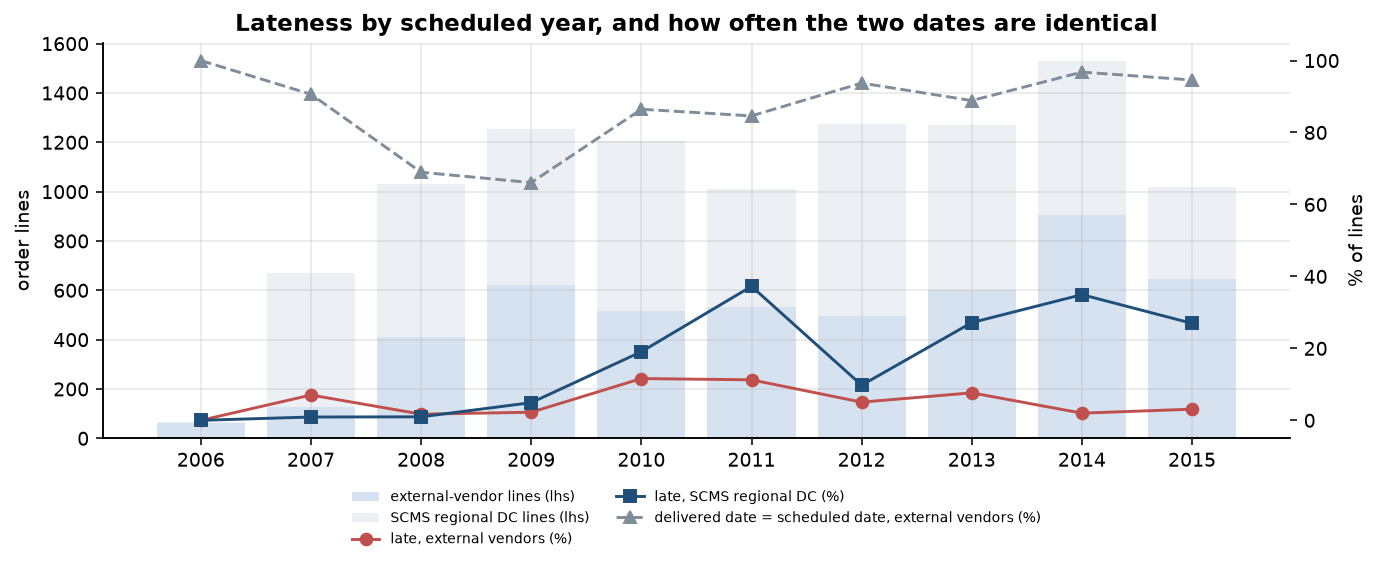

In [12]:
from IPython.display import Image; Image('docs/figures/programme_yearly_lateness.png', width=800)